# Phase 1: Enhancement (kritikaa, TUMOUR, patient 22)

| Step | This member's algorithms |
|---|---|
| Windowing | **liver window**, level 80 / width 200 (narrower than the abdomen window, so the tumour stands out more) |
| Spatial filter | **bilateral** (edge-preserving) vs **Gaussian** blur (required comparison) + **non-local means** (kritikaa's own filter, used in the final pipeline) |
| Contrast | **CLAHE** vs **histogram equalisation** (applied after non-local means) |
| Frequency | 2D DFT spectrum + **Butterworth lowpass** (D0 = 50, order 3), compared with a **Gaussian lowpass** (D0 = 50); spectrum shown before and after each |
| Validation | PSNR + CNR (liver vs surroundings, and the main target: **tumour vs liver**) + a controlled noise test (PSNR + SSIM against a known clean image) |

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

NAME = "kritikaa"
SLICES = f"../data/slices/{NAME}"
OUT = "outputs_kritikaa"
FIGS = "../report/figures/kritikaa"
os.makedirs(f"{OUT}/enhanced", exist_ok=True)
os.makedirs(FIGS, exist_ok=True)

files = sorted(glob.glob(f"{SLICES}/*_ct.npy"))
print(len(files), "slices found")

def load(ct_path):
    base = ct_path.replace("_ct.npy", "")
    return np.load(ct_path), cv2.imread(base + "_liver.png", 0) > 0, cv2.imread(base + "_tumour.png", 0) > 0

example = max(files, key=lambda f: load(f)[2].sum())     # slice with the biggest tumour
ct, liver, tumour = load(example)
print("example slice:", os.path.basename(example), "| tumour pixels:", tumour.sum())
print("median HU  liver:", np.median(ct[liver & ~tumour]), " tumour:", np.median(ct[tumour]))

12 slices found
example slice: p22_s132_ct.npy | tumour pixels: 1239
median HU  liver: 104.0  tumour: 43.0


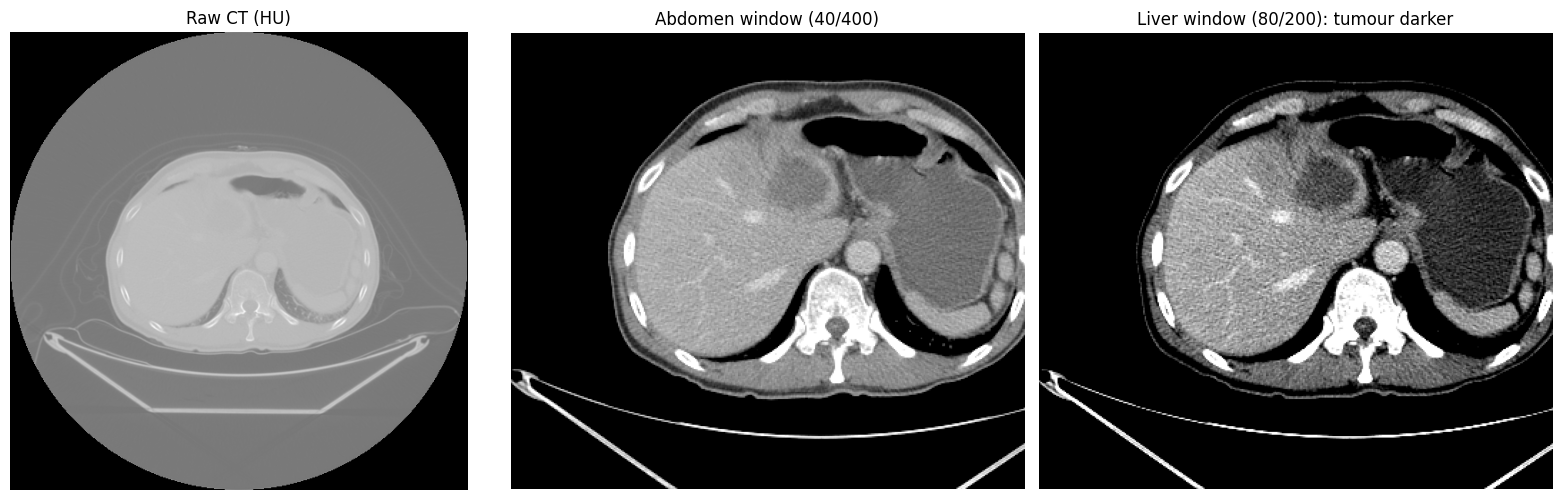

In [2]:
def window(ct, level=80, width=200):
    lo, hi = level - width / 2, level + width / 2          # 80, 200 -> -20 to 180 HU
    return ((np.clip(ct, lo, hi) - lo) / (hi - lo) * 255).astype(np.uint8)

def crop(img):
    return img[100:420, 40:400]

def abdomen(ct):
    return ((np.clip(ct, -160, 240) + 160) / 400 * 255).astype(np.uint8)

win = window(ct)
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(ct, cmap="gray"); ax[0].set_title("Raw CT (HU)")
ax[1].imshow(crop(abdomen(ct)), cmap="gray"); ax[1].set_title("Abdomen window (40/400)")
ax[2].imshow(crop(win), cmap="gray"); ax[2].set_title("Liver window (80/200): tumour darker")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_windowing.png", dpi=120); plt.show()

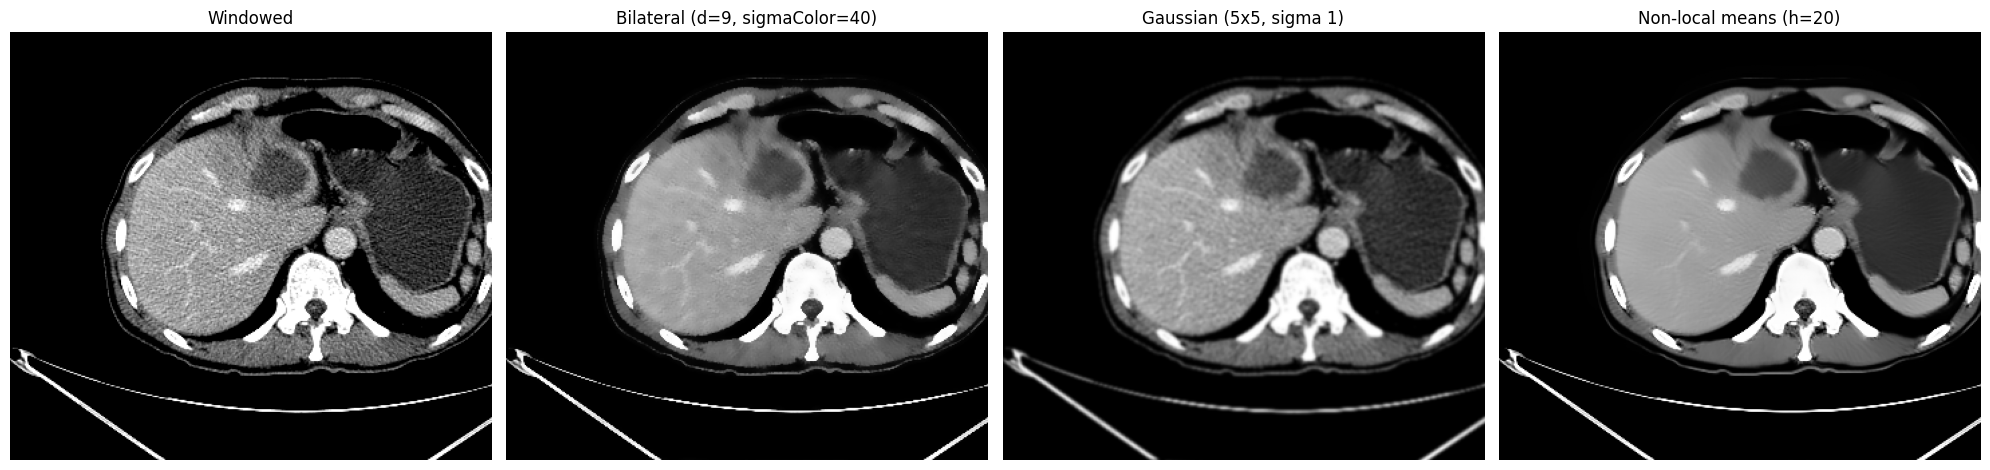

In [3]:
NLM_H = 20     # non-local means strength: how different two patches may be and still be averaged

def nlm(img, h=NLM_H):
    """Non-local means: each pixel becomes a weighted average of pixels whose 7x7 NEIGHBOURHOOD looks similar,
    searched in a 21x21 window. Similar patches anywhere nearby are averaged, so flat liver is smoothed
    while the tumour border (a different-looking patch) is kept."""
    return cv2.fastNlMeansDenoising(img, None, h=h, templateWindowSize=7, searchWindowSize=21)

bilateral = cv2.bilateralFilter(win, d=9, sigmaColor=40, sigmaSpace=9)
gauss = cv2.GaussianBlur(win, (5, 5), 1)
nonlocal_means = nlm(win)
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, im, t in zip(ax, [win, bilateral, gauss, nonlocal_means],
                    ["Windowed", "Bilateral (d=9, sigmaColor=40)", "Gaussian (5x5, sigma 1)", f"Non-local means (h={NLM_H})"]):
    a.imshow(crop(im), cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_spatial_filters.png", dpi=120); plt.show()

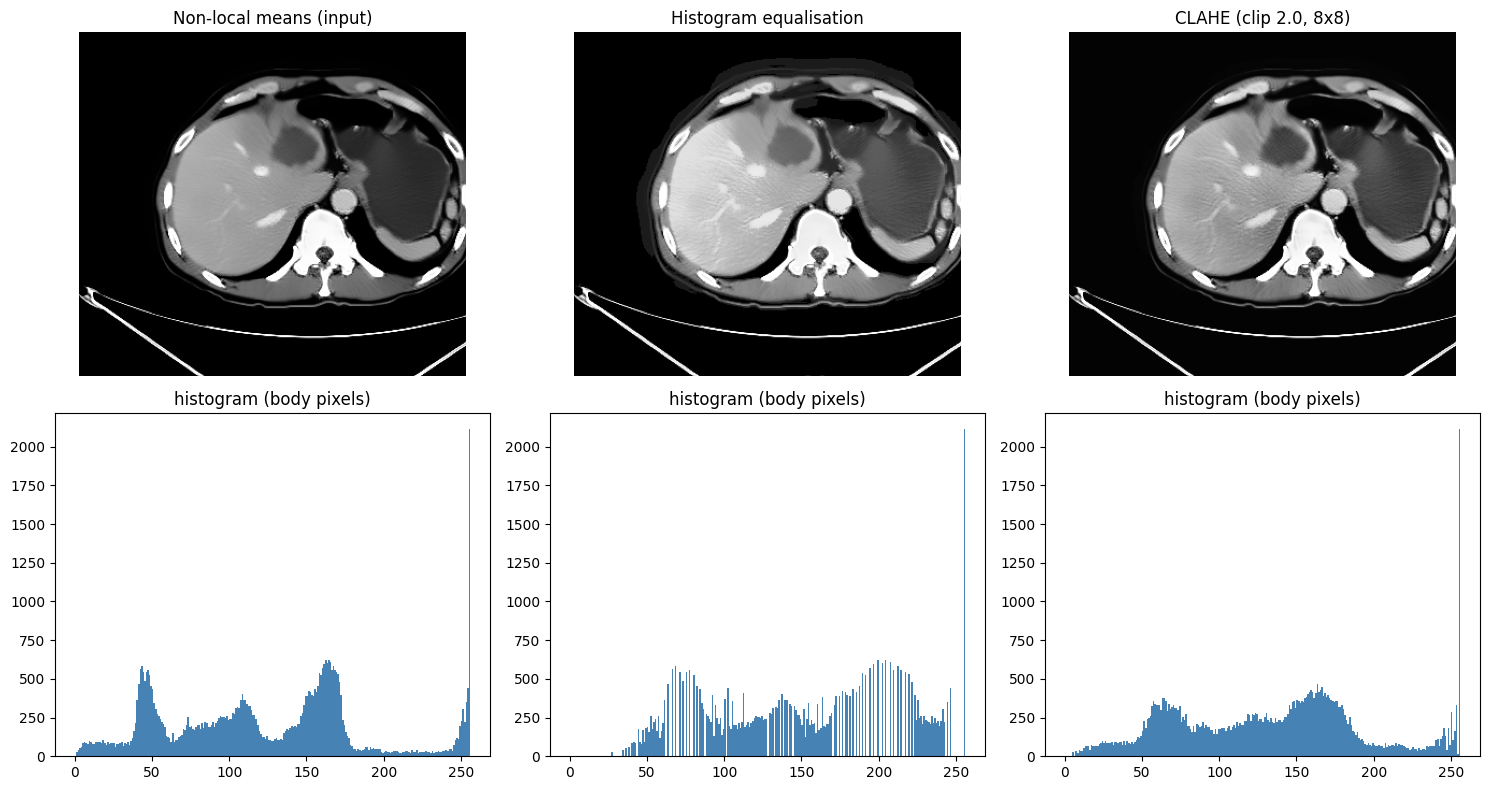

In [4]:
he = cv2.equalizeHist(nonlocal_means)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(nonlocal_means)
body = win > 0
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j, (im, t) in enumerate([(nonlocal_means, "Non-local means (input)"), (he, "Histogram equalisation"), (clahe, "CLAHE (clip 2.0, 8x8)")]):
    ax[0, j].imshow(crop(im), cmap="gray"); ax[0, j].set_title(t); ax[0, j].axis("off")
    ax[1, j].hist(im[body].ravel(), bins=256, range=(0, 256), color="steelblue"); ax[1, j].set_title("histogram (body pixels)")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_contrast.png", dpi=120); plt.show()

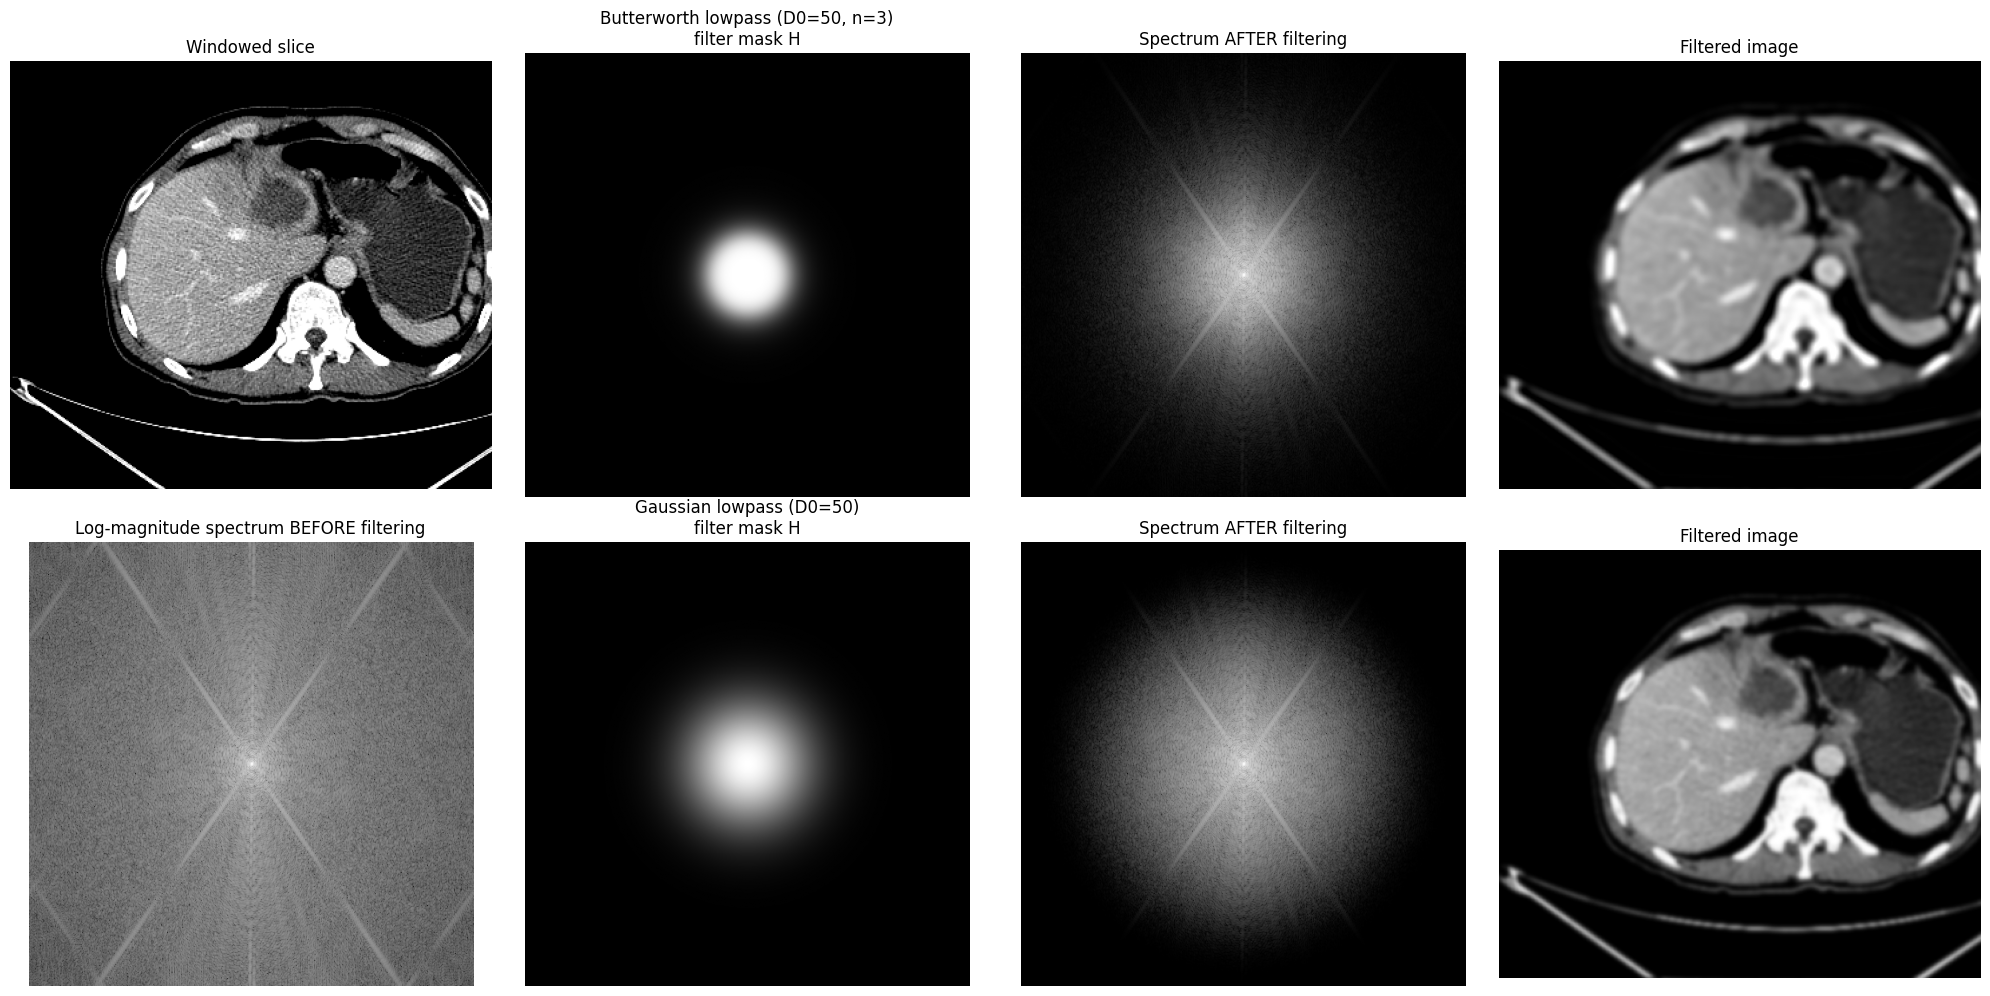

In [5]:
def spectrum(img):
    """Centred 2D DFT of an image (zero frequency in the middle)."""
    return np.fft.fftshift(np.fft.fft2(img.astype(np.float64)))

def distance_grid(shape):
    rows, cols = shape
    u, v = np.meshgrid(np.arange(cols) - cols / 2, np.arange(rows) - rows / 2)
    return np.sqrt(u ** 2 + v ** 2)                       # distance of each frequency from the centre

def apply_mask(img, H):
    F = spectrum(img)
    out = np.real(np.fft.ifft2(np.fft.ifftshift(F * H)))
    return np.clip(out, 0, 255).astype(np.uint8), F, F * H

def butterworth_lowpass(img, D0=50, n=3):
    """Required filter. Keep low frequencies (smooth shapes), cut high ones (noise); smooth roll-off of order n."""
    H = 1 / (1 + (distance_grid(img.shape) / D0) ** (2 * n))
    out, F, _ = apply_mask(img, H)
    return out, F, H

def gaussian_lowpass(img, D0=50):
    """kritikaa's extra comparison: Gaussian-shaped lowpass, H = exp(-D^2 / 2 D0^2). No ringing at all,
    but it also cuts some middle frequencies the Butterworth keeps."""
    H = np.exp(-distance_grid(img.shape) ** 2 / (2 * D0 ** 2))
    out, F, _ = apply_mask(img, H)
    return out, F, H

log_mag = lambda F: np.log(1 + np.abs(F))
butter, F, H_b = butterworth_lowpass(win)
glp, _, H_g = gaussian_lowpass(win)
fig, ax = plt.subplots(2, 4, figsize=(20, 10))
ax[0, 0].imshow(crop(win), cmap="gray"); ax[0, 0].set_title("Windowed slice")
ax[1, 0].imshow(log_mag(F), cmap="gray"); ax[1, 0].set_title("Log-magnitude spectrum BEFORE filtering")
for r, (H, out, t) in enumerate([(H_b, butter, "Butterworth lowpass (D0=50, n=3)"), (H_g, glp, "Gaussian lowpass (D0=50)")]):
    ax[r, 1].imshow(H, cmap="gray"); ax[r, 1].set_title(t + "\nfilter mask H")
    ax[r, 2].imshow(log_mag(F * H), cmap="gray"); ax[r, 2].set_title("Spectrum AFTER filtering")
    ax[r, 3].imshow(crop(out), cmap="gray"); ax[r, 3].set_title("Filtered image")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_frequency.png", dpi=120); plt.show()

In [6]:
def psnr(ref, test):
    """How close the processed image stays to the reference (dB). Higher = closer."""
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

def cnr(img, region, background):
    """How well a region stands out from its background. Higher = easier to see."""
    a, b = img[region].astype(np.float64), img[background].astype(np.float64)
    if len(a) == 0 or len(b) == 0:
        return np.nan
    return abs(a.mean() - b.mean()) / np.sqrt(a.var() + b.var() + 1e-9)

rows = []
for f in files:
    ct, liver, tumour = load(f)
    win = window(ct)
    nl = nlm(win)
    versions = {"windowed": win, "bilateral": cv2.bilateralFilter(win, 9, 40, 9), "gaussian": cv2.GaussianBlur(win, (5, 5), 1),
                "non-local means": nl, "butterworth": butterworth_lowpass(win)[0], "gaussian lowpass": gaussian_lowpass(win)[0],
                "nlm+HE": cv2.equalizeHist(nl), "nlm+CLAHE": cv2.createCLAHE(2.0, (8, 8)).apply(nl)}
    ring = cv2.dilate(liver.astype(np.uint8), np.ones((25, 25), np.uint8)).astype(bool) & ~liver
    for method, im in versions.items():
        rows.append({"slice": os.path.basename(f)[:-7], "method": method,
                     "PSNR": np.nan if method == "windowed" else psnr(win, im),   # vs windowed: only "how much it changed"
                     "CNR liver vs surroundings": cnr(im, liver, ring),          # soft tissue vs background
                     "CNR tumour vs liver": cnr(im, tumour, liver & ~tumour)})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/phase1_metrics.csv", index=False)
print(results.groupby("method", sort=False)[["PSNR", "CNR liver vs surroundings", "CNR tumour vs liver"]].mean().round(2))

                   PSNR  CNR liver vs surroundings  CNR tumour vs liver
method                                                                 
windowed            NaN                       0.72                 1.69
bilateral         31.78                       0.75                 2.38
gaussian          26.95                       0.79                 2.32
non-local means   30.87                       0.75                 2.52
butterworth       23.46                       0.80                 2.41
gaussian lowpass  24.32                       0.82                 2.41
nlm+HE            23.87                       0.88                 2.29
nlm+CLAHE         28.10                       0.73                 2.36


**Controlled noise test.** PSNR against the windowed slice only says how much a filter *changed* the image, not whether it improved it. Here the windowed slice is treated as the clean reference, Gaussian noise with a known strength (sigma = 40 HU, added to the CT **before** windowing, so every member's window scales it like real CT noise; 40 HU is well above the CT's own noise) is added, and each filter has to remove it. PSNR and SSIM (structural similarity: 1 = same structure) are measured against the clean slice, on tissue pixels only (not on clipped black air or white bone), so higher really means "closer to the truth". (The windowed slice already contains some CT noise, so this measures how well each filter removes *added* noise.)

In [7]:
from skimage.metrics import structural_similarity as ssim

NOISE_SIGMA_HU = 40      # same physical noise for every member, added in HU BEFORE windowing
noise_rng = np.random.default_rng(0)
rows = []
for f in files:
    ct = load(f)[0]
    clean = window(ct)
    noisy = window(ct + noise_rng.normal(0, NOISE_SIGMA_HU, ct.shape))   # each window scales the noise like real CT noise
    # score only tissue that is not clipped in the clean slice: in black air / white bone the noise can only go one way
    # and is clipped away, which would reward filters (e.g. median) just for restoring flat black or white areas
    tissue = (clean > 0) & (clean < 255)
    filtered = {"noisy (no filter)": noisy, "bilateral": cv2.bilateralFilter(noisy, 9, 40, 9),
                "gaussian": cv2.GaussianBlur(noisy, (5, 5), 1), "non-local means": nlm(noisy),
                "butterworth": butterworth_lowpass(noisy)[0], "gaussian lowpass": gaussian_lowpass(noisy)[0]}
    for method, im in filtered.items():
        _, ssim_map = ssim(clean, im, data_range=255, full=True)
        rows.append({"slice": os.path.basename(f)[:-7], "method": method,
                     "PSNR vs clean": psnr(clean[tissue], im[tissue]), "SSIM vs clean": ssim_map[tissue].mean()})
noise_test = pd.DataFrame(rows)
noise_test.to_csv(f"{OUT}/phase1_noise_test.csv", index=False)
print(f"Added Gaussian noise in HU, sigma = {NOISE_SIGMA_HU} HU (before windowing):")
print(noise_test.groupby("method", sort=False)[["PSNR vs clean", "SSIM vs clean"]].mean().round(3))

Added Gaussian noise in HU, sigma = 40 HU (before windowing):
                   PSNR vs clean  SSIM vs clean
method                                         
noisy (no filter)         14.639          0.459
bilateral                 16.927          0.526
gaussian                  19.939          0.570
non-local means           14.737          0.458
butterworth               18.142          0.383
gaussian lowpass          18.753          0.442


**Final enhancement chosen:** liver window -> non-local means (h = 20) -> CLAHE. Non-local means gives the highest tumour CNR of the spatial filters, and the active contour in Phase 2 worked best on the CLAHE version (see the Phase 2 notebook). The Butterworth and Gaussian lowpass filters are shown for the frequency-domain comparison and are not used in the final pipeline.

In [8]:
for f in files:
    ct, _, _ = load(f)
    enh = cv2.createCLAHE(2.0, (8, 8)).apply(nlm(window(ct)))
    cv2.imwrite(f"{OUT}/enhanced/{os.path.basename(f).replace('_ct.npy', '_enh.png')}", enh)
print("saved", len(files), "enhanced slices to", f"{OUT}/enhanced")

saved 12 enhanced slices to outputs_kritikaa/enhanced
